## Configure API keys

- Open your [`Roboflow Settings`](https://app.roboflow.com/settings/api) page. Click `Copy`. This will place your private key in the clipboard.
- In Colab, go to the left pane and click on `Secrets` (🔑). Store Roboflow API Key under the name `ROBOFLOW_API_KEY`.

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install dependencies

In [4]:
!pip install -q modal roboflow

## Imports

In [5]:
import os
import sys
import modal
from google.colab import userdata
from IPython.display import Image, display

for name in [
    "MODAL_TOKEN_ID",
    "MODAL_TOKEN_SECRET",
    "ROBOFLOW_API_KEY",
]:
    os.environ[name] = userdata.get(name).strip()

pitch_app = modal.App("pitch-keypoint-training")

PITCH_GPU = "A100-80GB"

pitch_python = (
    f"{sys.version_info.major}.{sys.version_info.minor}"
)

pitch_image = (
    modal.Image.debian_slim(python_version=pitch_python)
    .apt_install("libgl1", "libglib2.0-0")
    .pip_install(
        "ultralytics==8.4.193",
        "roboflow",
        "pyyaml",
    )
)

pitch_secret = modal.Secret.from_dict({
    "ROBOFLOW_API_KEY": os.environ["ROBOFLOW_API_KEY"],
})

pitch_volume = modal.Volume.from_name(
    "pitch-keypoints-v15",
    create_if_missing=True,
    version=2,
)

## Pull dataset

In [6]:
@pitch_app.function(
    image=pitch_image,
    secrets=[pitch_secret],
    volumes={"/storage": pitch_volume},
    timeout=1800,
)
def prepare_pitch_dataset():
    import os
    from pathlib import Path
    import yaml
    from roboflow import Roboflow

    root = Path("/storage/dataset")
    marker = root / ".ready"
    yaml_path = root / "data.yaml"

    if not marker.exists():
        rf = Roboflow(
            api_key=os.environ["ROBOFLOW_API_KEY"]
        )

        project = rf.workspace("roboflow-jvuqo").project(
            "football-field-detection-f07vi"
        )

        project.version(15).download(
            "yolov8",
            location=str(root),
        )

        config = yaml.safe_load(yaml_path.read_text())

        if "kpt_shape" not in config:
            raise ValueError(
                "data.yaml thiếu kpt_shape; "
                "cần kiểm tra đúng bản export keypoints."
            )

        train_images = root / "train/images"
        val_images = next(
            (
                root / split / "images"
                for split in ("valid", "val")
                if (root / split / "images").is_dir()
            ),
            None,
        )

        assert train_images.is_dir(), "Thiếu train/images"
        assert val_images is not None, "Thiếu ảnh validation"

        config["path"] = str(root)
        config["train"] = str(train_images)
        config["val"] = str(val_images)

        if (root / "test/images").is_dir():
            config["test"] = str(root / "test/images")
        else:
            config.pop("test", None)

        # Giữ kpt_shape, flip_idx, names và metadata khác.
        yaml_path.write_text(
            yaml.safe_dump(config, sort_keys=False)
        )

        marker.touch()
        pitch_volume.commit()

    print(yaml_path.read_text())


with modal.enable_output():
    with pitch_app.run():
        prepare_pitch_dataset.remote()

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-r8TWaqsmCq7b1S856TpYyF
Building image im-TuX6Z06wEjwJhZPzSj5lFw

=> Step 0: FROM base

=> Step 1: RUN python -m pip install pyyaml roboflow ultralytics==8.4.193
Looking in indexes: http://pypi-mirror.modal.local:5555/simple
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 291.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 1.3 GB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 511.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.4 GB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 795.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 776.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 836.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 733.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 779.6 MB/s eta 0:00:00

**NOTE:** Update `data.yaml` structure to align with the latest requirements of the `ultralytics` package.

## Custom training

In [7]:
@pitch_app.function(
    image=pitch_image,
    gpu=PITCH_GPU,
    cpu=4,
    memory=16384,
    volumes={"/storage": pitch_volume},
    timeout=4 * 60 * 60,
)
def train_pitch(epochs: int = 100, batch_size: int = 16):
    from datetime import datetime
    from pathlib import Path
    import torch
    from ultralytics import YOLO

    pitch_volume.reload()

    assert Path("/storage/dataset/.ready").exists(), (
        "Chạy prepare_pitch_dataset trước."
    )

    print("GPU train:", torch.cuda.get_device_name(0))
    print(
        "VRAM GiB:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            1,
        ),
    )

    run_name = datetime.now().strftime(
        "pitch-%Y%m%d-%H%M%S"
    )

    model = YOLO("yolov8x-pose.pt")

    def persist_checkpoint(trainer):
        pitch_volume.commit()

    model.add_callback("on_model_save", persist_checkpoint)

    try:
        model.train(
            task="pose",
            data="/storage/dataset/data.yaml",
            batch=batch_size,
            epochs=epochs,
            imgsz=640,
            mosaic=0.0,
            plots=True,
            amp=True,
            device=0,
            workers=4,
            cache=False,
            save=True,
            project="/storage/runs",
            name=run_name,
        )

        return run_name

    finally:
        pitch_volume.commit()

In [8]:
with modal.enable_output():
    with pitch_app.run():
        PITCH_RUN_NAME = train_pitch.remote(
            epochs=100,
            batch_size=16,
        )

print("Run chính:", PITCH_RUN_NAME)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-2Yew9dVUdjJAuwgAdJX8nf
✓ Created objects.
├── ✓ Created Function prepare_pitch_dataset.
└── ✓ Created Function train_pitch.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU train: NVIDIA A100-SXM4-80GB
VRAM GiB: 79.3
Ultralytics 8.4.193 🚀 Python-3.13.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100-SXM4-80GB, 81175MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/storage/dataset/data.yaml, degrees=0.

In [9]:
from pathlib import Path
import tempfile
import subprocess

# Thư mục mới để tránh lỗi trùng file/thư mục lần trước.
PITCH_LOCAL_RUN = Path(tempfile.mkdtemp(
    prefix="pitch-results-",
    dir="/content",
))

filenames = [
    "results.png",
    "results.csv",
    "args.yaml",
    "val_batch0_pred.jpg",
    "val_batch0_labels.jpg",
    "weights/best.pt",
    "weights/last.pt",
]

for filename in filenames:
    destination = PITCH_LOCAL_RUN / filename
    destination.parent.mkdir(parents=True, exist_ok=True)

    result = subprocess.run(
        [
            "modal", "volume", "get",
            "pitch-keypoints-v15",
            f"/runs/{PITCH_RUN_NAME}/{filename}",
            str(destination),
            "--force",
        ],
        capture_output=True,
        text=True,
    )

    if result.returncode == 0:
        print("Đã tải:", filename)
    else:
        print("Không tải được:", filename)
        print(result.stderr.strip())

print("Thư mục kết quả:", PITCH_LOCAL_RUN)

Đã tải: results.png
Đã tải: results.csv
Đã tải: args.yaml
Đã tải: val_batch0_pred.jpg
Đã tải: val_batch0_labels.jpg
Đã tải: weights/best.pt
Đã tải: weights/last.pt
Thư mục kết quả: /content/pitch-results-zdbais90


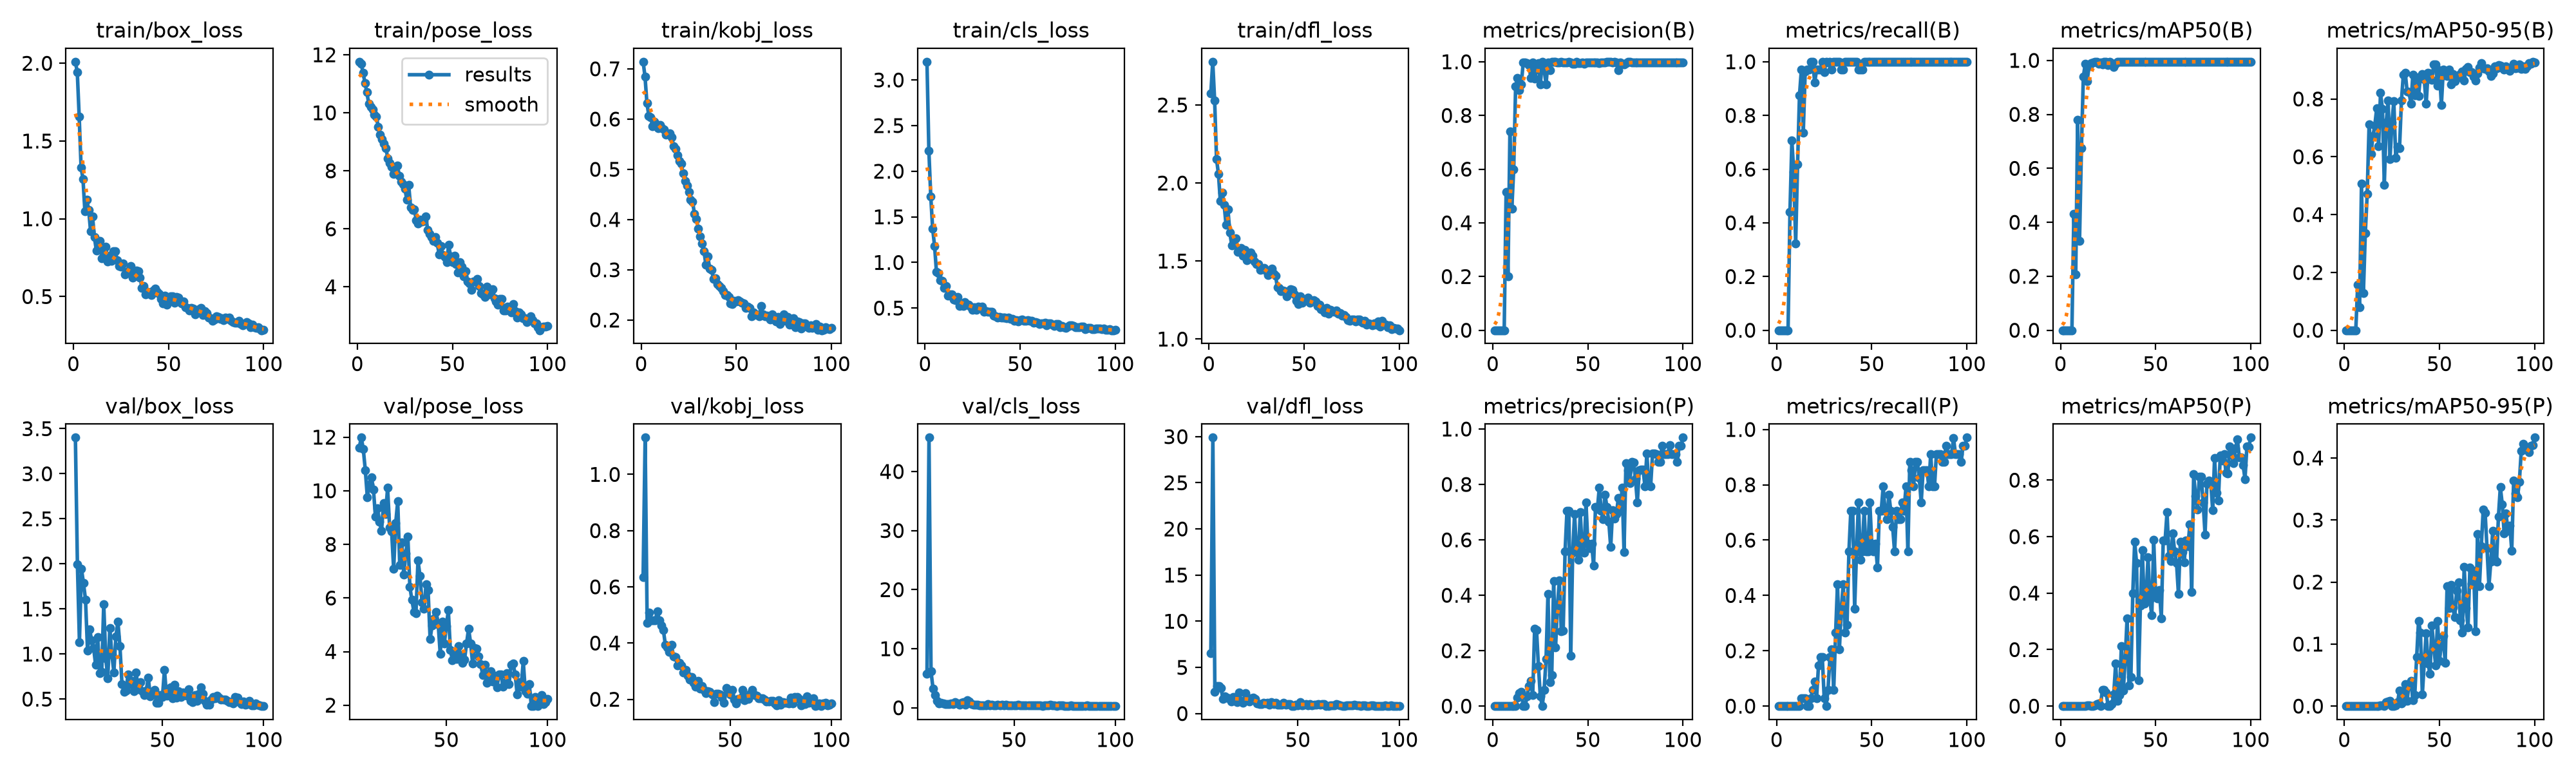

In [10]:
display(Image(
    filename=str(PITCH_LOCAL_RUN / "results.png"),
    width=1000,
))

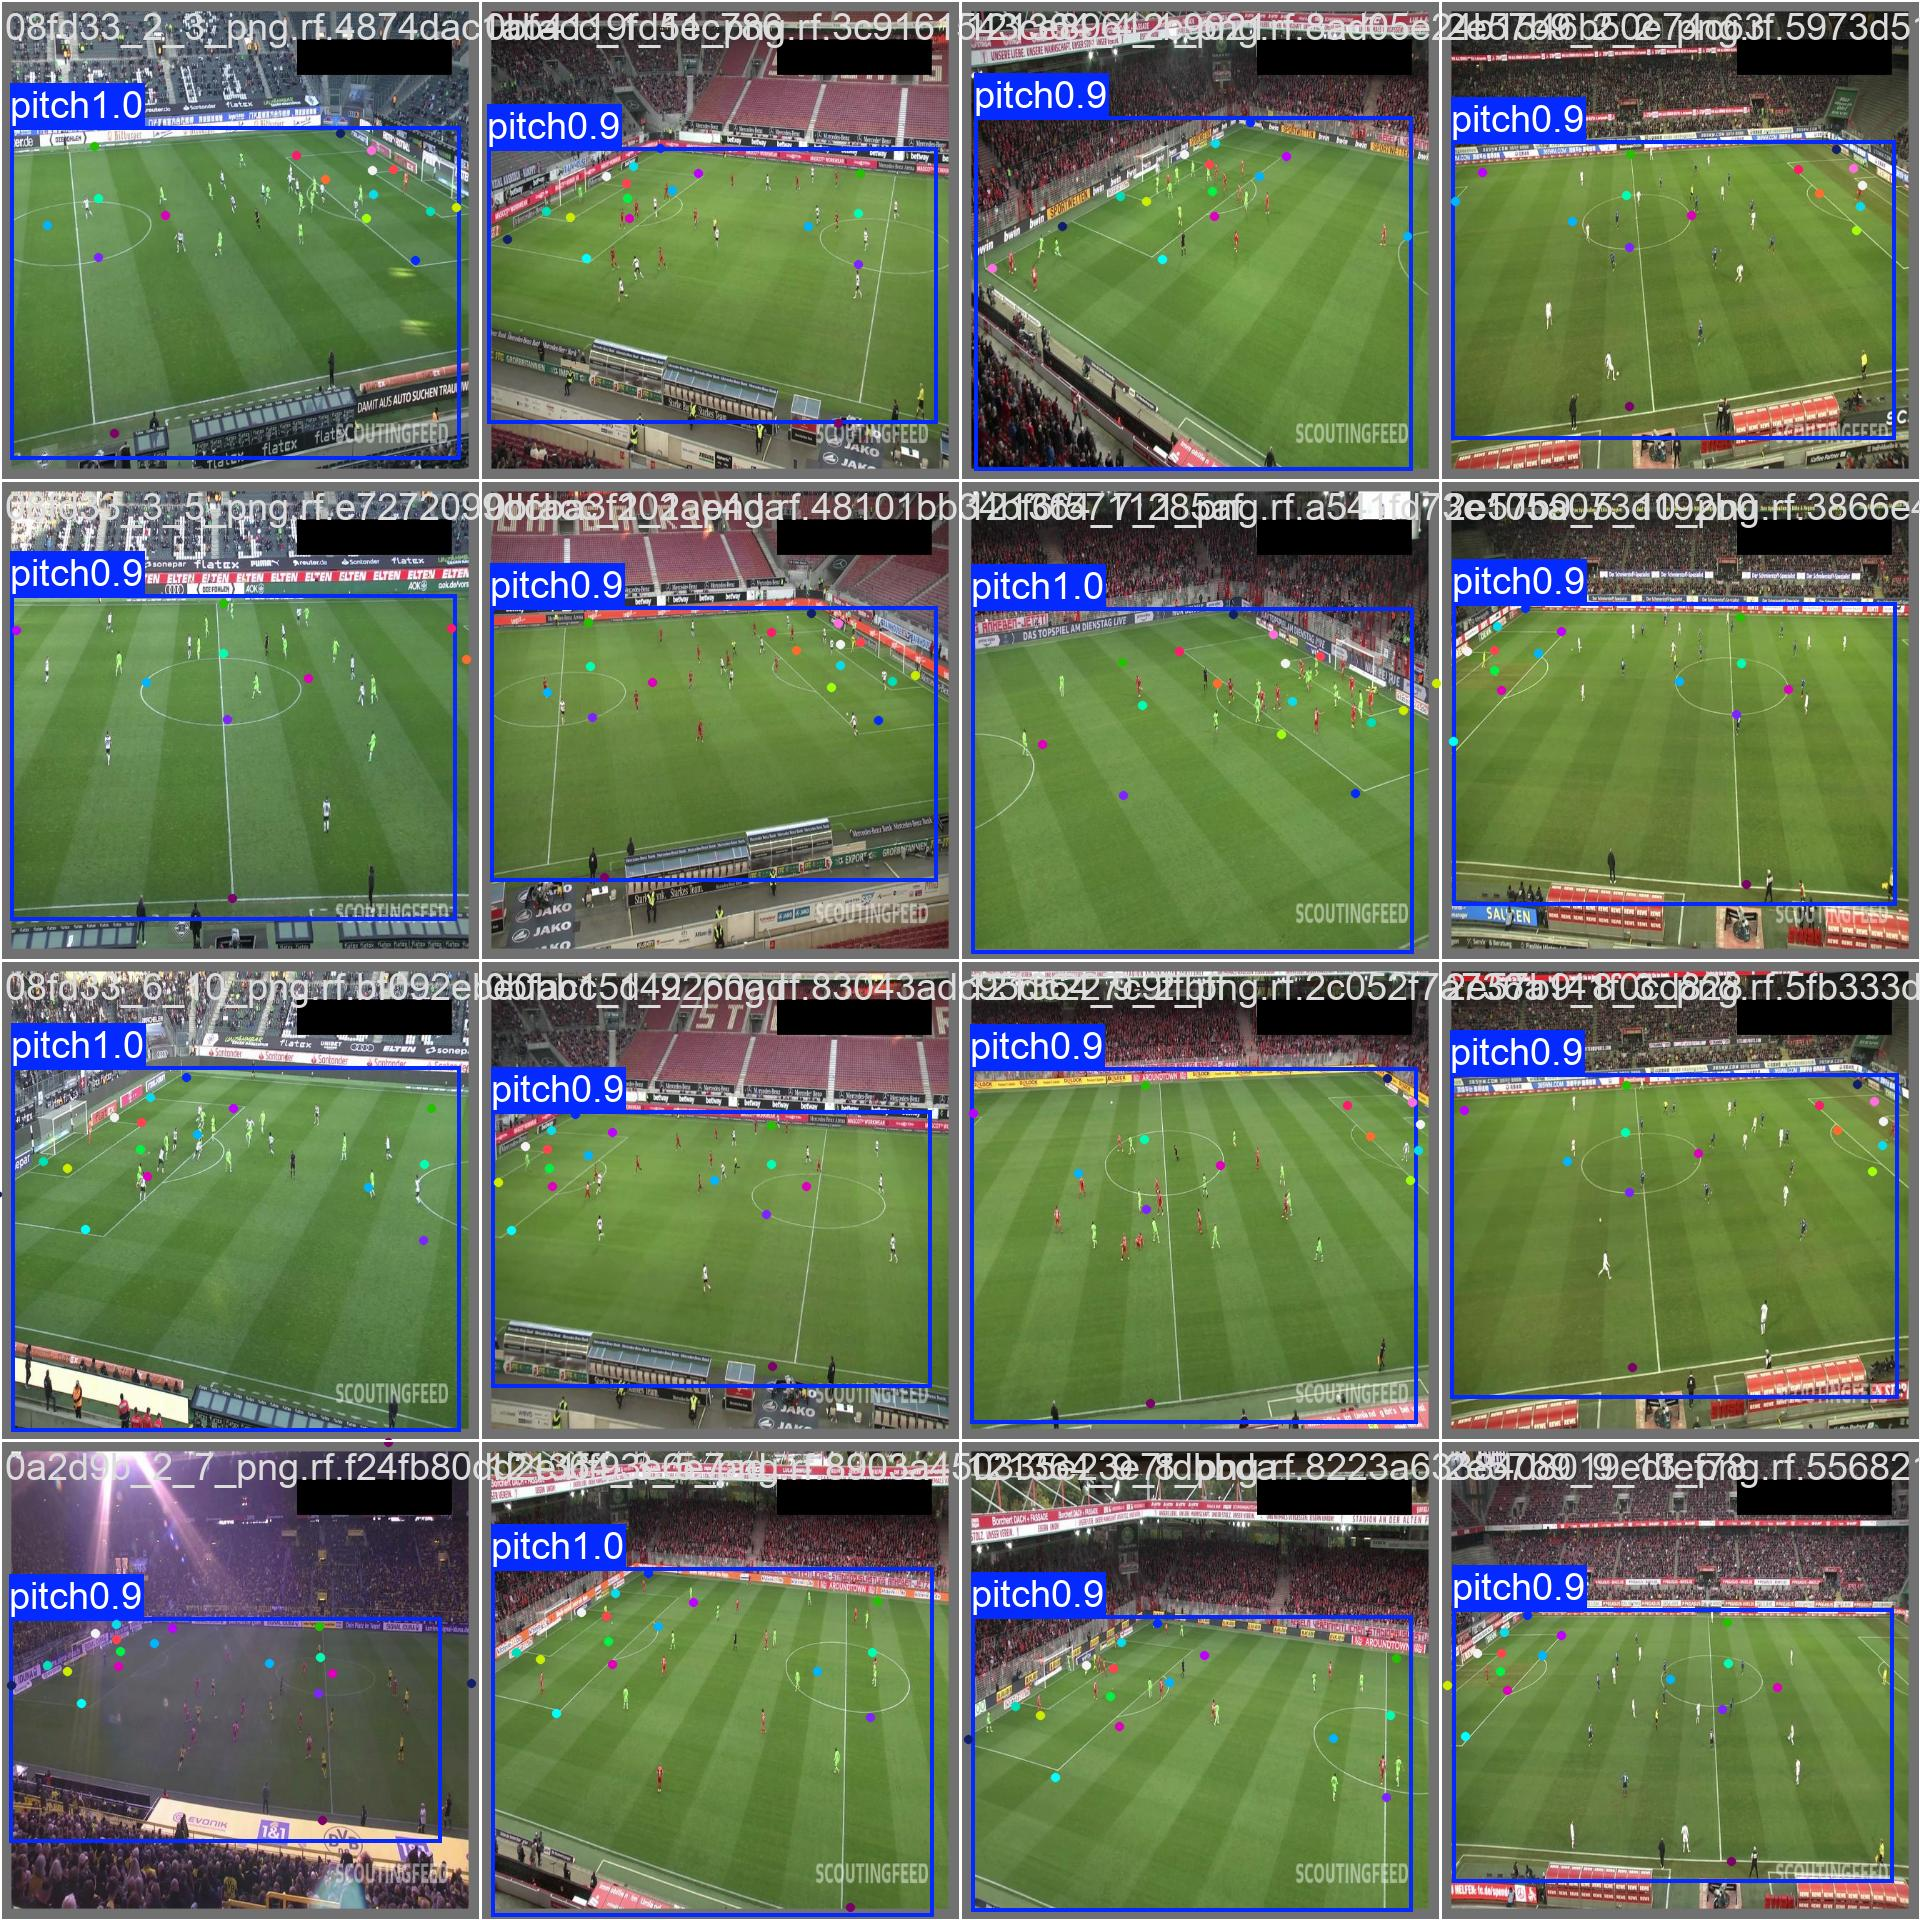

In [12]:
display(Image(
    filename=str(PITCH_LOCAL_RUN / "val_batch0_pred.jpg"),
    width=1000,
))

## Validate custom model

In [13]:
@pitch_app.function(
    image=pitch_image,
    gpu=PITCH_GPU,
    volumes={"/storage": pitch_volume},
    timeout=1800,
)
def validate_pitch(run_name: str):
    from ultralytics import YOLO

    pitch_volume.reload()

    model = YOLO(
        f"/storage/runs/{run_name}/weights/best.pt"
    )

    try:
        metrics = model.val(
            data="/storage/dataset/data.yaml",
            split="val",
            imgsz=640,
            batch=16,
            device=0,
            plots=True,
            project="/storage/evaluations",
            name=run_name,
            exist_ok=True,
        )

        return {
            "box_mAP50": float(metrics.box.map50),
            "box_mAP50_95": float(metrics.box.map),
            "pose_mAP50": float(metrics.pose.map50),
            "pose_mAP50_95": float(metrics.pose.map),
        }
    finally:
        pitch_volume.commit()


with modal.enable_output():
    with pitch_app.run():
        pitch_metrics = validate_pitch.remote(PITCH_RUN_NAME)

print(pitch_metrics)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-HyvYa1LUcnWmNoDfYweSBk
✓ Created objects.
├── ✓ Created Function prepare_pitch_dataset.
├── ✓ Created Function train_pitch.
└── ✓ Created Function validate_pitch.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.193 🚀 Python-3.13.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100-SXM4-80GB, 81175MiB)
YOLOv8x-pose summary (fused): 121 layers, 69,784,275 parameters, 0 gradients, 264.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 52.3±47.9 MB/s, size: 65.0 KB)
val: Scanning /__modal/volumes/vo-h9xfOi9OV0i9ddvwwJBK6D/dataset/valid/labels.cache... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 5.7Mit/s 0.0s
                 Class     Images  Instances 

[modal-client] 2026-10-30T05:30:09+0000 Timed out waiting for final app logs.


✓ App completed. View run at 
https://modal.com/apps/luluchi19/main/ap-HyvYa1LUcnWmNoDfYweSBk
{'box_mAP50': 0.995, 'box_mAP50_95': 0.9258702202425905, 'pose_mAP50': 0.897941176470588, 'pose_mAP50_95': 0.4196931054458754}


## Deploy model on Roboflow

In [14]:
from pathlib import Path
from roboflow import Roboflow
from google.colab import userdata

model_dir = Path(PITCH_LOCAL_RUN)

assert (model_dir / "weights/best.pt").is_file(), (
    f"Không tìm thấy: {model_dir / 'weights/best.pt'}"
)

rf = Roboflow(
    api_key=userdata.get("ROBOFLOW_API_KEY").strip()
)

pitch_project = rf.workspace(
    "nguyns-workspace-do3bt"
).project(
    "football-field-detection-f07vi-gh8mi"
)

pitch_project.version(1).deploy(
    model_type="yolov8-pose",
    model_path=str(model_dir),
    filename="weights/best.pt",
)

loading Roboflow workspace...
loading Roboflow project...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics==8.0.196 is recommended for this upload, but ultralytics 8.4.193 is installed. Retry with allow_dependency_mismatch=True to package with the installed version, or `pip install ultralytics==8.0.196`.
Would you like to continue anyway? y/n: y
ultralytics==8.0.196 is recommended for this upload, but ultralytics 8.4.193 is installed.
Inferred model size 'yolov8x' from the checkpoint architecture (model_type was 'yolov8-pose').
View the status of your deployment at: https://app.roboflow.com/nguyns-workspace-do3bt/football-field-detection-f07vi-gh8mi/1
